Saving GooglePayIndia_EDA.csv to GooglePayIndia_EDA.csv
EDA dataset loaded successfully.
STEP 3 - NLP / TEXT ANALYSIS

Dataset Shape:
(34219, 14)

Columns:
['reviewId', 'userName', 'content', 'score', 'thumbsUpCount', 'reviewCreatedVersion', 'at', 'replyContent', 'repliedAt', 'sentiment', 'year', 'month', 'year_month', 'has_reply']

Reviews available for NLP: 34219

Original Review:
How do add a boarding pass? I see no passes tab.

Cleaned Review:
add boarding pass see passes tab

REVIEW LENGTH ANALYSIS
         word_count  character_count
count  34219.000000     34219.000000
mean       7.266256        80.883632
std        9.079675       106.582766
min        0.000000         1.000000
25%        2.000000        13.000000
50%        4.000000        37.000000
75%        9.000000       103.000000
max      146.000000      1836.000000

TOP 30 MOST COMMON WORDS
card          4913
easy          3894
great         3212
good          3060
phone         3022
works         2531
work          2228

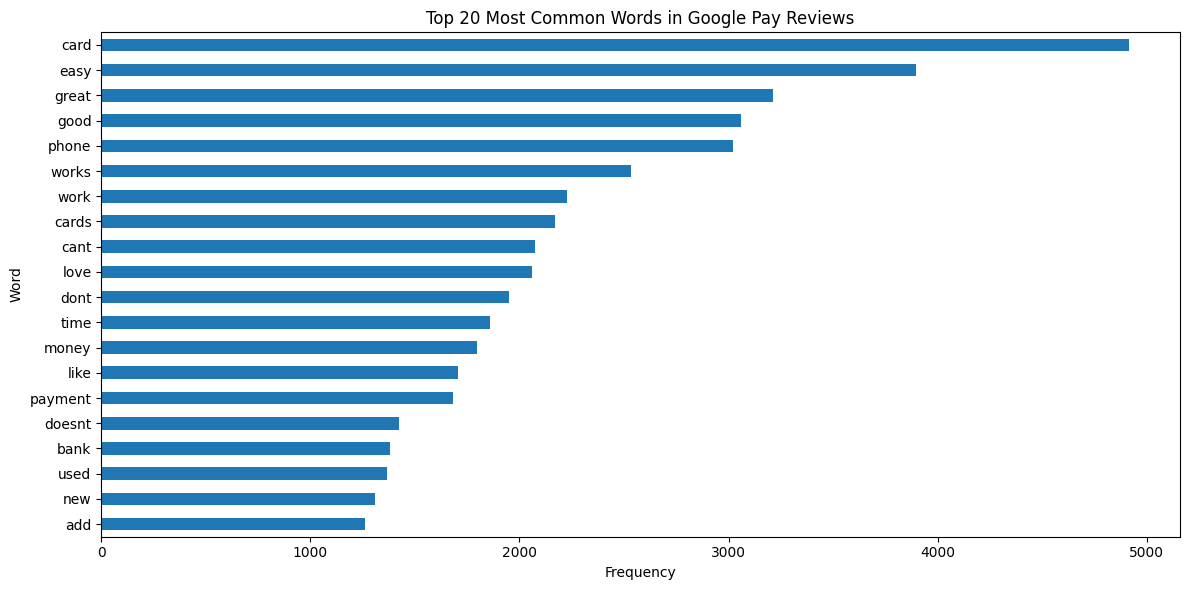


Creating Word Cloud...


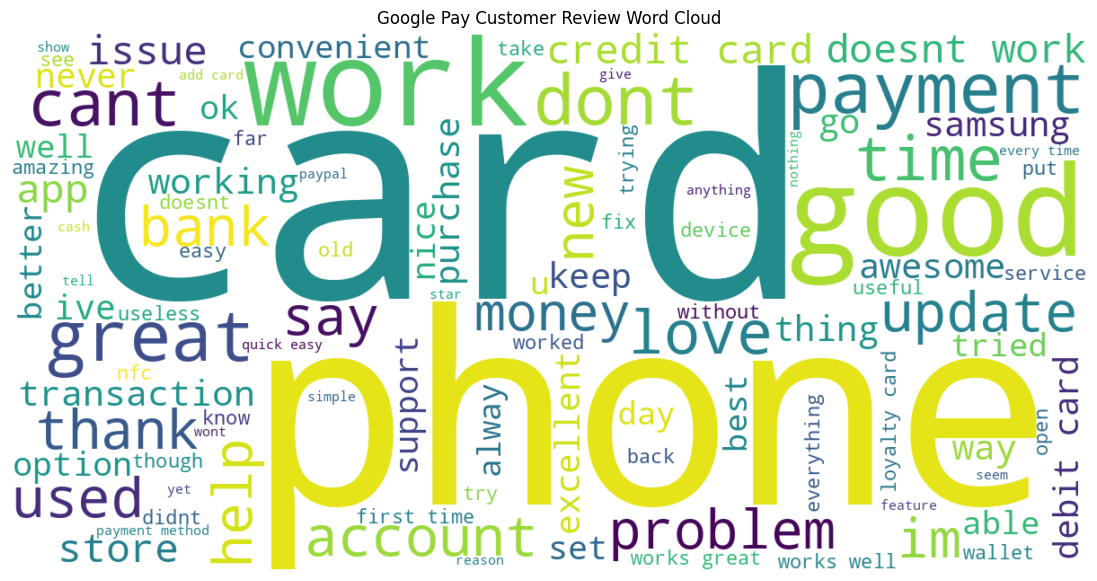


VADER SENTIMENT ANALYSIS

NLP Sentiment Counts:
nlp_sentiment
Positive    20245
Neutral      7193
Negative     6781
Name: count, dtype: int64

NLP Sentiment Percentage:
nlp_sentiment
Positive    59.16
Neutral     21.02
Negative    19.82
Name: proportion, dtype: float64


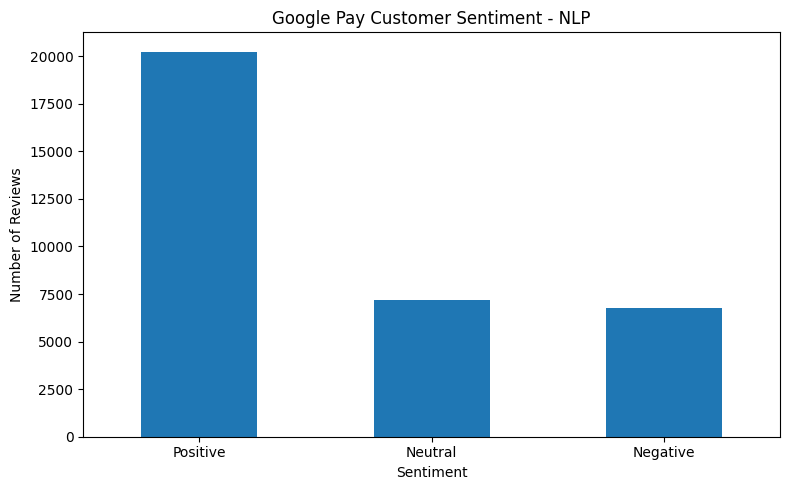


POSITIVE REVIEWS
Number of positive reviews: 20245

Examples:
 score                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                         content
     5                                                                                                                                                                                                                                                                                                                            

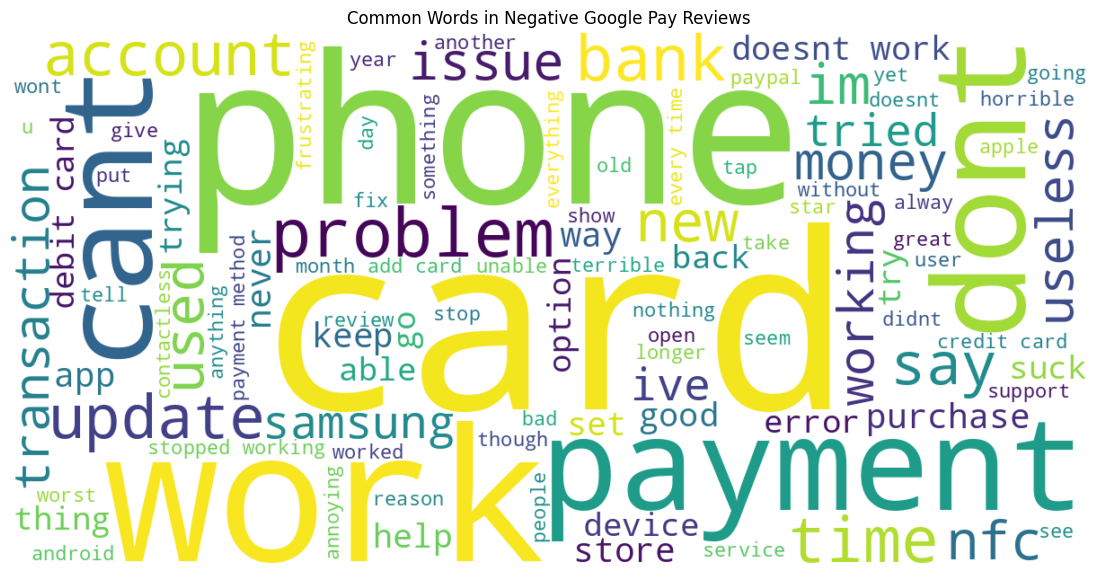


TOP WORDS IN POSITIVE REVIEWS
easy          3757
great         3056
good          2796
card          2556
love          1995
works         1651
phone         1426
cards         1337
like          1321
time          1009
dont           883
money          834
payment        813
work           794
cant           770
convenient     762
awesome        747
well           733
used           717
wallet         711
way            697
excellent      650
bank           625
credit         621
fast           610
new            610
add            608
im             599
nice           561
far            558
Name: count, dtype: int64


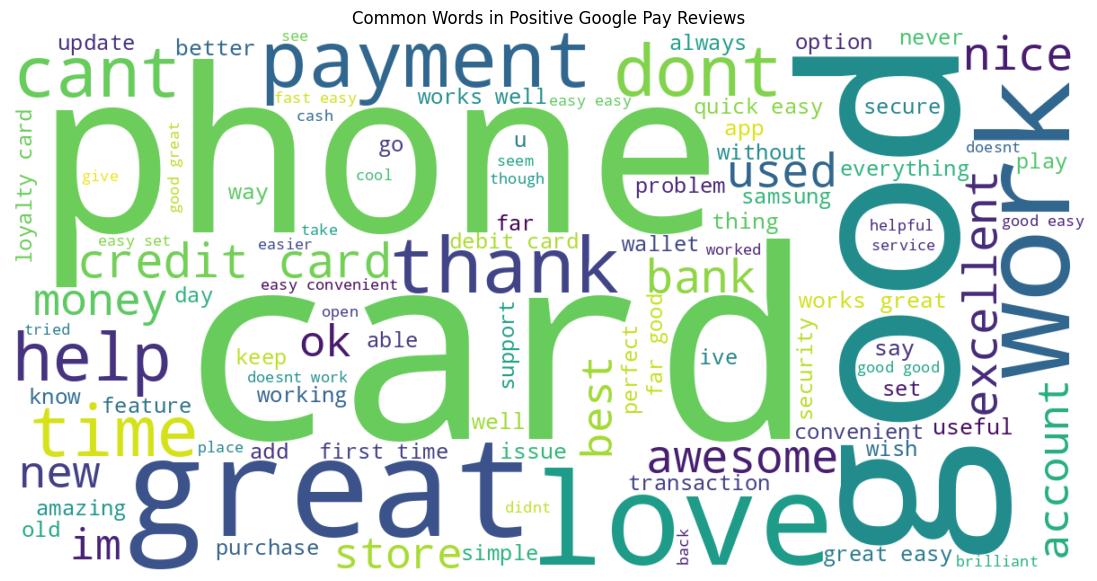


COMMON CUSTOMER ISSUES
                  Issue  Keyword_Mentions
4            Bank Issue              2061
0         Payment Issue              2007
2           Money Issue              1983
5       Technical Issue              1375
1    Transaction Failed               270
6           Login Issue               235
7  Server/Network Issue               163
3          Refund Issue               155


<Figure size 1000x600 with 0 Axes>

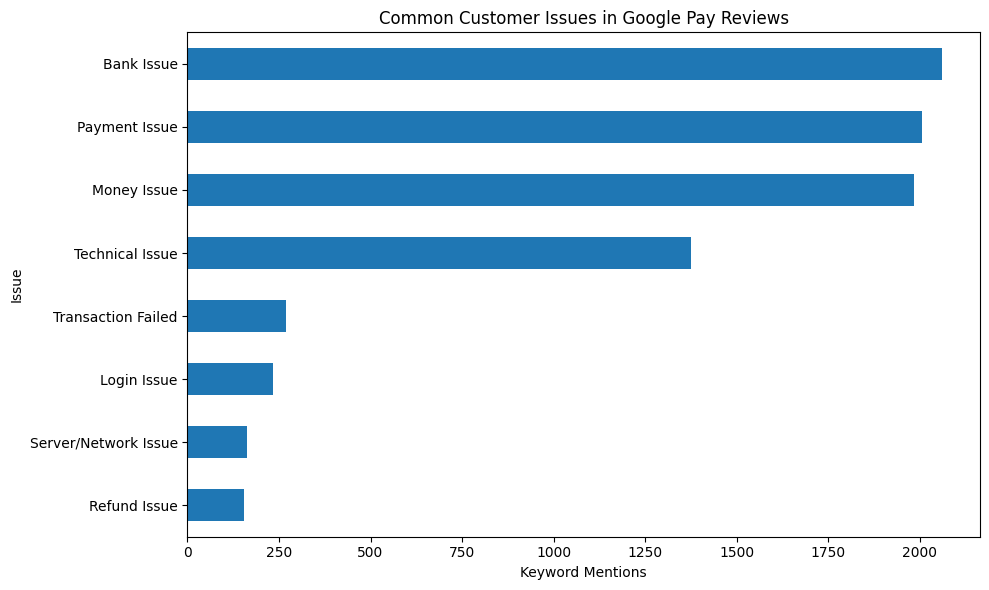


RATING SENTIMENT VS NLP SENTIMENT
nlp_sentiment  Negative  Neutral  Positive
sentiment                                 
Negative           4823     2735      2650
Neutral             517      528       883
Positive           1441     3930     16712

NLP SENTIMENT BY RATING
nlp_sentiment  Negative  Neutral  Positive
score                                     
1                  4165     2323      2128
2                   658      412       522
3                   517      528       883
4                   407      619      2016
5                  1034     3311     14696

Average NLP Sentiment Score by Rating:
score
1   -0.124640
2   -0.040718
3    0.122569
4    0.310566
5    0.430395
Name: sentiment_score, dtype: float64


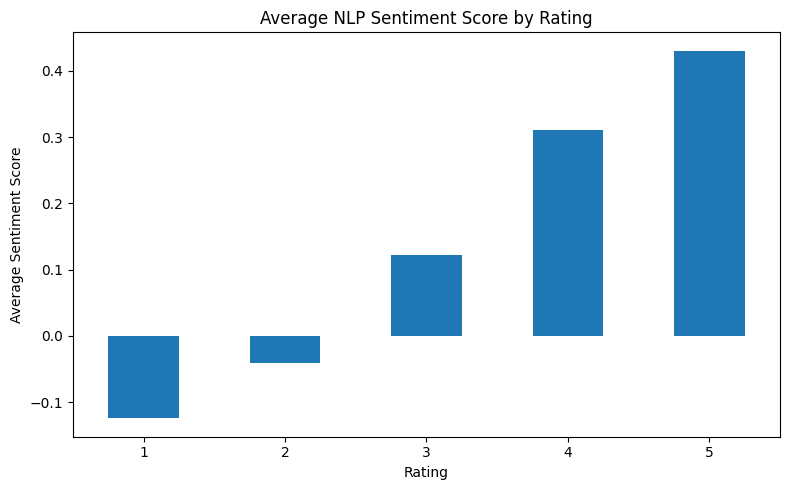


10 MOST NEGATIVE REVIEWS
 score  sentiment_score                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              content
     1          -0.9879          Very bad experience!!! I've had fraudulent charges show up on my bank account.. called and requested receipt and also disputed the charges. Just to have them send me a letter saying they weren't fraudulent charges and couldn't supply a receipt... ohhhh but they were fraudulent and this happened twice to me... google pay and google are very bad and dont protect you like they say!!!! DO NOT USE THIS APP.... If you 

In [2]:
# ============================================================
# GOOGLE PAY INDIA DATA ANALYSIS
# STEP 3: NLP / TEXT ANALYSIS
# ============================================================

# ------------------------------------------------------------
# 1. INSTALL / IMPORT LIBRARIES
# ------------------------------------------------------------

import sys
import subprocess
import importlib.util

# Install missing packages
packages = {
    "nltk": "nltk",
    "wordcloud": "wordcloud"
}

for module, package in packages.items():
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", package, "-q"
        ])

import pandas as pd
import numpy as np
import re
import string
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import stopwords
from nltk.sentiment import SentimentIntensityAnalyzer

from wordcloud import WordCloud


# ------------------------------------------------------------
# 2. DOWNLOAD NLTK RESOURCES
# ------------------------------------------------------------

nltk.download('stopwords', quiet=True)
nltk.download('vader_lexicon', quiet=True)


# ------------------------------------------------------------
# 3. LOAD DATASET
# ------------------------------------------------------------
from google.colab import files

uploaded = files.upload()
try:
    df = pd.read_csv("GooglePayIndia_EDA.csv")
    print("EDA dataset loaded successfully.")

except FileNotFoundError:
    try:
        df = pd.read_csv("GooglePayIndia_Cleaned.csv")
        print("Cleaned dataset loaded successfully.")

    except FileNotFoundError:
        print("Please upload GooglePayIndia_Cleaned.csv or GooglePayIndia_EDA.csv")
        raise


# ------------------------------------------------------------
# 4. BASIC INFORMATION
# ------------------------------------------------------------

print("=" * 70)
print("STEP 3 - NLP / TEXT ANALYSIS")
print("=" * 70)

print("\nDataset Shape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())


# ------------------------------------------------------------
# 5. HANDLE MISSING REVIEW TEXT
# ------------------------------------------------------------

df['content'] = df['content'].fillna('').astype(str)

# Remove completely empty reviews
df = df[df['content'].str.strip() != ''].copy()

print("\nReviews available for NLP:", len(df))


# ------------------------------------------------------------
# 6. TEXT CLEANING FUNCTION
# ------------------------------------------------------------

stop_words = set(stopwords.words('english'))

# Additional words that are not useful for our analysis
custom_stopwords = {
    'google',
    'pay',
    'gpay',
    'app',
    'application',
    'please',
    'use',
    'using',
    'get',
    'got',
    'one',
    'also',
    'can',
    'could',
    'would',
    'still',
    'really',
    'much',
    'even',
    'make',
    'made',
    'need',
    'want'
}

stop_words.update(custom_stopwords)


def clean_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', ' ', text)

    # Remove email addresses
    text = re.sub(r'\S+@\S+', ' ', text)

    # Remove HTML tags
    text = re.sub(r'<.*?>', ' ', text)

    # Remove numbers
    text = re.sub(r'\d+', ' ', text)

    # Remove punctuation
    text = text.translate(
        str.maketrans('', '', string.punctuation)
    )

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    # Remove stopwords
    words = [
        word for word in text.split()
        if word not in stop_words
    ]

    return ' '.join(words)


# ------------------------------------------------------------
# 7. CREATE CLEAN TEXT COLUMN
# ------------------------------------------------------------

df['clean_text'] = df['content'].apply(clean_text)

print("\nOriginal Review:")
print(df['content'].iloc[0])

print("\nCleaned Review:")
print(df['clean_text'].iloc[0])


# ------------------------------------------------------------
# 8. REVIEW LENGTH ANALYSIS
# ------------------------------------------------------------

df['word_count'] = df['clean_text'].apply(
    lambda x: len(x.split())
)

df['character_count'] = df['content'].apply(
    len
)

print("\n" + "=" * 70)
print("REVIEW LENGTH ANALYSIS")
print("=" * 70)

print(df[['word_count', 'character_count']].describe())


# ------------------------------------------------------------
# 9. MOST COMMON WORDS
# ------------------------------------------------------------

all_words = ' '.join(
    df['clean_text']
).split()

word_frequency = pd.Series(
    all_words
).value_counts()

print("\n" + "=" * 70)
print("TOP 30 MOST COMMON WORDS")
print("=" * 70)

print(word_frequency.head(30))


# ------------------------------------------------------------
# 10. MOST COMMON WORDS BAR CHART
# ------------------------------------------------------------

top_words = word_frequency.head(20)

plt.figure(figsize=(12, 6))

top_words.sort_values().plot(kind='barh')

plt.title("Top 20 Most Common Words in Google Pay Reviews")
plt.xlabel("Frequency")
plt.ylabel("Word")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. WORD CLOUD
# ------------------------------------------------------------

print("\nCreating Word Cloud...")

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    max_words=100
).generate(
    ' '.join(df['clean_text'])
)

plt.figure(figsize=(14, 7))

plt.imshow(
    wordcloud,
    interpolation='bilinear'
)

plt.axis('off')
plt.title("Google Pay Customer Review Word Cloud")

plt.show()


# ------------------------------------------------------------
# 12. VADER SENTIMENT ANALYSIS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("VADER SENTIMENT ANALYSIS")
print("=" * 70)

sia = SentimentIntensityAnalyzer()


def get_vader_sentiment(text):

    score = sia.polarity_scores(text)['compound']

    if score >= 0.05:
        return "Positive"

    elif score <= -0.05:
        return "Negative"

    else:
        return "Neutral"


def get_sentiment_score(text):

    return sia.polarity_scores(text)['compound']


df['nlp_sentiment'] = df['content'].apply(
    get_vader_sentiment
)

df['sentiment_score'] = df['content'].apply(
    get_sentiment_score
)


# ------------------------------------------------------------
# 13. NLP SENTIMENT DISTRIBUTION
# ------------------------------------------------------------

nlp_sentiment_counts = (
    df['nlp_sentiment']
    .value_counts()
)

print("\nNLP Sentiment Counts:")
print(nlp_sentiment_counts)


nlp_sentiment_percentage = (
    df['nlp_sentiment']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nNLP Sentiment Percentage:")
print(nlp_sentiment_percentage)


# ------------------------------------------------------------
# 14. NLP SENTIMENT CHART
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

nlp_sentiment_counts.plot(kind='bar')

plt.title("Google Pay Customer Sentiment - NLP")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 15. POSITIVE REVIEWS
# ------------------------------------------------------------

positive_reviews = df[
    df['nlp_sentiment'] == 'Positive'
]

print("\n" + "=" * 70)
print("POSITIVE REVIEWS")
print("=" * 70)

print("Number of positive reviews:",
      len(positive_reviews))

print("\nExamples:")

print(
    positive_reviews[
        ['score', 'content']
    ].head(10).to_string(index=False)
)


# ------------------------------------------------------------
# 16. NEGATIVE REVIEWS
# ------------------------------------------------------------

negative_reviews = df[
    df['nlp_sentiment'] == 'Negative'
]

print("\n" + "=" * 70)
print("NEGATIVE REVIEWS")
print("=" * 70)

print("Number of negative reviews:",
      len(negative_reviews))

print("\nExamples:")

print(
    negative_reviews[
        ['score', 'content']
    ].head(10).to_string(index=False)
)


# ------------------------------------------------------------
# 17. NEUTRAL REVIEWS
# ------------------------------------------------------------

neutral_reviews = df[
    df['nlp_sentiment'] == 'Neutral'
]

print("\n" + "=" * 70)
print("NEUTRAL REVIEWS")
print("=" * 70)

print("Number of neutral reviews:",
      len(neutral_reviews))


# ------------------------------------------------------------
# 18. COMMON WORDS IN NEGATIVE REVIEWS
# ------------------------------------------------------------

negative_words = ' '.join(
    negative_reviews['clean_text']
).split()

negative_word_frequency = pd.Series(
    negative_words
).value_counts()

print("\n" + "=" * 70)
print("TOP WORDS IN NEGATIVE REVIEWS")
print("=" * 70)

print(
    negative_word_frequency.head(30)
)


# ------------------------------------------------------------
# 19. NEGATIVE WORD CLOUD
# ------------------------------------------------------------

if len(negative_words) > 0:

    negative_wordcloud = WordCloud(
        width=1200,
        height=600,
        background_color='white',
        max_words=100
    ).generate(
        ' '.join(negative_reviews['clean_text'])
    )

    plt.figure(figsize=(14, 7))

    plt.imshow(
        negative_wordcloud,
        interpolation='bilinear'
    )

    plt.axis('off')

    plt.title(
        "Common Words in Negative Google Pay Reviews"
    )

    plt.show()


# ------------------------------------------------------------
# 20. COMMON WORDS IN POSITIVE REVIEWS
# ------------------------------------------------------------

positive_words = ' '.join(
    positive_reviews['clean_text']
).split()

positive_word_frequency = pd.Series(
    positive_words
).value_counts()

print("\n" + "=" * 70)
print("TOP WORDS IN POSITIVE REVIEWS")
print("=" * 70)

print(
    positive_word_frequency.head(30)
)


# ------------------------------------------------------------
# 21. POSITIVE WORD CLOUD
# ------------------------------------------------------------

if len(positive_words) > 0:

    positive_wordcloud = WordCloud(
        width=1200,
        height=600,
        background_color='white',
        max_words=100
    ).generate(
        ' '.join(positive_reviews['clean_text'])
    )

    plt.figure(figsize=(14, 7))

    plt.imshow(
        positive_wordcloud,
        interpolation='bilinear'
    )

    plt.axis('off')

    plt.title(
        "Common Words in Positive Google Pay Reviews"
    )

    plt.show()


# ------------------------------------------------------------
# 22. COMMON CUSTOMER ISSUES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("COMMON CUSTOMER ISSUES")
print("=" * 70)

issue_keywords = {
    'Payment Issue': [
        'payment',
        'pay',
        'transaction',
        'transfer'
    ],

    'Transaction Failed': [
        'failed',
        'failure',
        'declined',
        'unsuccessful'
    ],

    'Money Issue': [
        'money',
        'cash',
        'amount',
        'balance'
    ],

    'Refund Issue': [
        'refund',
        'refunded',
        'return'
    ],

    'Bank Issue': [
        'bank',
        'account',
        'upi'
    ],

    'Technical Issue': [
        'error',
        'bug',
        'crash',
        'problem',
        'issue'
    ],

    'Login Issue': [
        'login',
        'signin',
        'sign',
        'otp',
        'password'
    ],

    'Server/Network Issue': [
        'server',
        'network',
        'internet',
        'connection'
    ]
}


issue_results = {}

for issue, keywords in issue_keywords.items():

    count = 0

    for keyword in keywords:

        count += df['clean_text'].str.contains(
            r'\b' + re.escape(keyword) + r'\b',
            regex=True,
            na=False
        ).sum()

    issue_results[issue] = count


issue_df = pd.DataFrame(
    list(issue_results.items()),
    columns=[
        'Issue',
        'Keyword_Mentions'
    ]
)

issue_df = issue_df.sort_values(
    'Keyword_Mentions',
    ascending=False
)

print(issue_df)


# ------------------------------------------------------------
# 23. CUSTOMER ISSUE CHART
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

issue_df.sort_values(
    'Keyword_Mentions'
).plot(
    x='Issue',
    y='Keyword_Mentions',
    kind='barh',
    legend=False,
    figsize=(10, 6)
)

plt.title("Common Customer Issues in Google Pay Reviews")
plt.xlabel("Keyword Mentions")
plt.ylabel("Issue")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 24. COMPARE RATING SENTIMENT VS NLP SENTIMENT
# ------------------------------------------------------------

if 'sentiment' in df.columns:

    comparison = pd.crosstab(
        df['sentiment'],
        df['nlp_sentiment']
    )

    print("\n" + "=" * 70)
    print("RATING SENTIMENT VS NLP SENTIMENT")
    print("=" * 70)

    print(comparison)


# ------------------------------------------------------------
# 25. NLP SENTIMENT BY RATING
# ------------------------------------------------------------

sentiment_by_rating = pd.crosstab(
    df['score'],
    df['nlp_sentiment']
)

print("\n" + "=" * 70)
print("NLP SENTIMENT BY RATING")
print("=" * 70)

print(sentiment_by_rating)


# ------------------------------------------------------------
# 26. AVERAGE NLP SENTIMENT SCORE BY RATING
# ------------------------------------------------------------

avg_sentiment_by_rating = (
    df.groupby('score')['sentiment_score']
    .mean()
)

print("\nAverage NLP Sentiment Score by Rating:")
print(avg_sentiment_by_rating)


plt.figure(figsize=(8, 5))

avg_sentiment_by_rating.plot(
    kind='bar'
)

plt.title(
    "Average NLP Sentiment Score by Rating"
)

plt.xlabel("Rating")
plt.ylabel("Average Sentiment Score")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 27. MOST NEGATIVE REVIEWS
# ------------------------------------------------------------

most_negative = (
    df.sort_values(
        'sentiment_score'
    )
    [['score', 'sentiment_score', 'content']]
    .head(10)
)

print("\n" + "=" * 70)
print("10 MOST NEGATIVE REVIEWS")
print("=" * 70)

print(
    most_negative.to_string(index=False)
)


# ------------------------------------------------------------
# 28. MOST POSITIVE REVIEWS
# ------------------------------------------------------------

most_positive = (
    df.sort_values(
        'sentiment_score',
        ascending=False
    )
    [['score', 'sentiment_score', 'content']]
    .head(10)
)

print("\n" + "=" * 70)
print("10 MOST POSITIVE REVIEWS")
print("=" * 70)

print(
    most_positive.to_string(index=False)
)


# ------------------------------------------------------------
# 29. REVIEW LENGTH BY SENTIMENT
# ------------------------------------------------------------

review_length_sentiment = (
    df.groupby('nlp_sentiment')['word_count']
    .mean()
    .round(2)
)

print("\nAverage Review Length by Sentiment:")
print(review_length_sentiment)


# ------------------------------------------------------------
# 30. SAVE NLP DATASET
# ------------------------------------------------------------

df.to_csv(
    "GooglePayIndia_NLP.csv",
    index=False
)

issue_df.to_csv(
    "GooglePayIndia_Customer_Issues.csv",
    index=False
)

print("\n" + "=" * 70)
print("STEP 3 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Files created:")

print("1. GooglePayIndia_NLP.csv")
print("2. GooglePayIndia_Customer_Issues.csv")


# ------------------------------------------------------------
# 31. FINAL NLP SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL NLP SUMMARY")
print("=" * 70)

print("Total Reviews Analyzed :", len(df))

print(
    "Positive Reviews       :",
    (df['nlp_sentiment'] == 'Positive').sum()
)

print(
    "Neutral Reviews        :",
    (df['nlp_sentiment'] == 'Neutral').sum()
)

print(
    "Negative Reviews       :",
    (df['nlp_sentiment'] == 'Negative').sum()
)

print(
    "Average Review Words   :",
    round(df['word_count'].mean(), 2)
)

print("\nTop 10 Overall Words:")
print(word_frequency.head(10))

print("\nTop 10 Negative Words:")
print(negative_word_frequency.head(10))

print("\nTop 10 Positive Words:")
print(positive_word_frequency.head(10))

print("\nTop Customer Issues:")
print(issue_df.head(10))

print("\nSTEP 3 DONE!")